# Plotting and interactive exports

Create readable genomic profiles, uncertainty bands, histograms, box plots, heatmaps and circular tracks. Static Matplotlib figures are suitable for publication and sharing; the app's headless plot renderer can also produce interactive HTML without launching the app.

Run all cells in order with DNAscape installed. Inputs are small synthetic arrays and need no downloads. Exports go to `examples/outputs/plotting/`.

1. Profiles and uncertainty
2. Distributions and statistics
3. Heatmaps and logarithmic colour
4. Interactive circular tracks
5. Export and navigation


In [1]:
from pathlib import Path
import os
import sys

# Works with Jupyter started in the repository root or in examples/.
PROJECT_DIR = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "dnascape" / "__init__.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start Jupyter inside your DNAscape checkout.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
OUTPUT_DIR = (
    Path(
        os.environ.get("DNASCAPE_NOTEBOOK_OUTPUT", PROJECT_DIR / "examples" / "outputs")
    )
    / "plotting"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dnascape import plotf, mplotf
from dnascape.workflows.preview import (
    PreviewLine,
    PreviewBand,
    build_preview_plot_options,
)
from dnascape.workflows.circular import circular_preview_options
from dnascape.workflows.plotting import write_plot_html

plt.rcParams.update(
    {
        "figure.figsize": (8, 3.2),
        "figure.dpi": 100,
        "axes.grid": False,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=["#b03412", "#3498b8", "#68615b"]),
    }
)
print(f"Outputs: {OUTPUT_DIR}")


Outputs: C:\Users\Francisco Berkemeier\Dropbox\Main Work\PostDoc\My Papers\DNAscape\github\DNAscape-devmode\examples\outputs\plotting


## 1. Profiles and uncertainty

Keep genomic coordinates separate from time coordinates. The synthetic ensemble below has a known mean profile and independent variation; the shaded band describes its standard deviation, not a confidence interval.


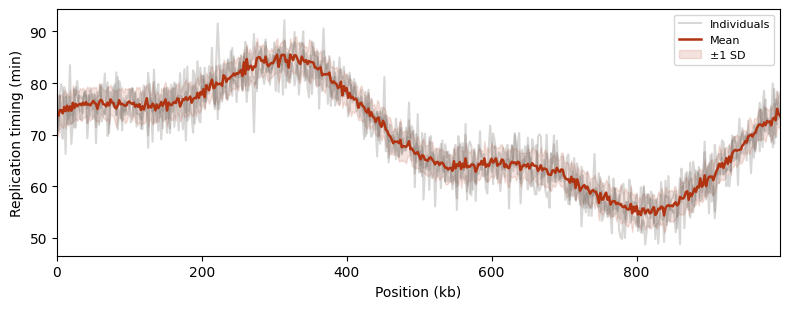

In [2]:
rng = np.random.default_rng(61)
positions_kb = np.arange(500) * 2.0
mean_profile = (
    70.0
    + 12 * np.sin(2 * np.pi * positions_kb / 1000.0)
    + 4 * np.cos(6 * np.pi * positions_kb / 1000.0)
)
individual_profiles = mean_profile[None, :] + rng.normal(
    0.0, 3.0, (24, positions_kb.size)
)
mean = individual_profiles.mean(axis=0)
std = individual_profiles.std(axis=0)
fig, ax = plt.subplots()
for index, values in enumerate(individual_profiles[:3]):
    ax.plot(
        positions_kb,
        values,
        alpha=0.25,
        color="#68615b",
        label="Individuals" if index == 0 else None,
    )
ax.plot(positions_kb, mean, color="#b03412", label="Mean", linewidth=1.8)
ax.fill_between(
    positions_kb, mean - std, mean + std, color="#b03412", alpha=0.14, label="±1 SD"
)
ax.set(
    xlabel="Position (kb)",
    ylabel="Replication timing (min)",
    xlim=(positions_kb[0], positions_kb[-1]),
)
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "timing_mean_sd.svg", bbox_inches="tight")
plt.show()


### Stack related tracks

`plotf` draws a single panel; `mplotf` aligns several panels. Provide the correct x axis to each track rather than relying on array indices. Here the derivative is an illustrative spatial feature, not a fitted fork-directionality measurement.


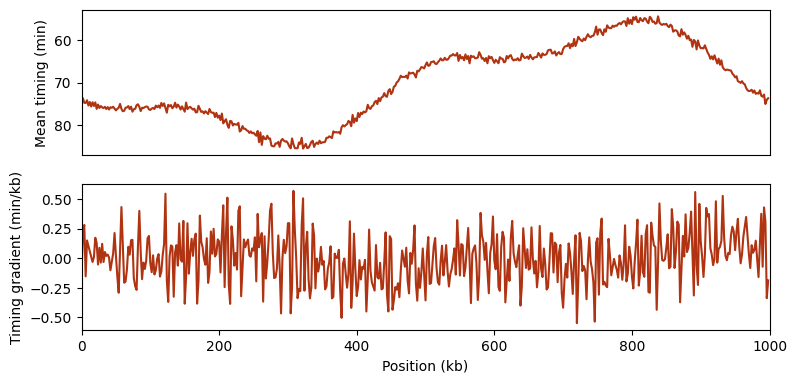

In [3]:
mplotf(
    [mean, np.gradient(mean, positions_kb)],
    mx_array=[positions_kb, positions_kb],
    mxtitle=["", "Position (kb)"],
    mytitle=["Mean timing (min)", "Timing gradient (min/kb)"],
    minvyQ=[True, False],
    figsize=(8, 2),
    hspace=0.2,
)


## 2. Distributions and statistics

Use count histograms for event totals, or density histograms when comparing distribution shapes. KDE bandwidth controls smoothness and does not change the underlying samples. Shared bin edges make two populations directly comparable.


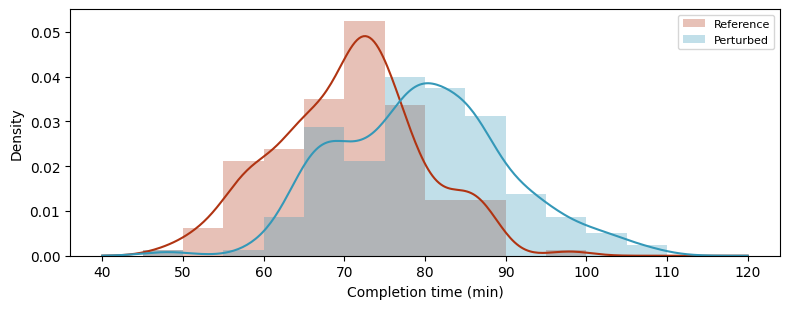

,n,Mean,Median,SD
Reference,160.0,70.58,71.26,8.94
Perturbed,160.0,79.72,79.56,10.32


In [4]:
from scipy.stats import gaussian_kde

samples = {
    "Reference": rng.normal(70.0, 8.0, 160),
    "Perturbed": rng.normal(80.0, 11.0, 160),
}
edges = np.arange(40.0, 121.0, 5.0)
fig, ax = plt.subplots()
for (label, values), color in zip(samples.items(), ["#b03412", "#3498b8"]):
    ax.hist(values, bins=edges, density=True, alpha=0.3, label=label, color=color)
    kde = gaussian_kde(values, bw_method=0.3)
    domain = np.linspace(edges[0], edges[-1], 300)
    ax.plot(domain, kde(domain), color=color)
ax.set(xlabel="Completion time (min)", ylabel="Density")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()
statistics = pd.DataFrame(
    {
        label: {
            "n": len(values),
            "Mean": values.mean(),
            "Median": np.median(values),
            "SD": values.std(),
        }
        for label, values in samples.items()
    }
).T
statistics.to_csv(OUTPUT_DIR / "statistics.tsv", sep="	", index_label="Dataset")
statistics.round(2)


### Editable box positions and labels

A box plot summarises distributions. Keep each box centred on its tick and choose meaningful labels. The explicit positions below can also represent a numeric experimental parameter.


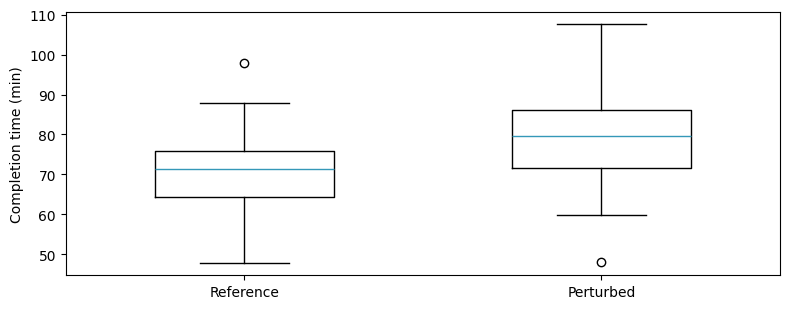

In [5]:
box_positions = [1.0, 2.0]
fig, ax = plt.subplots()
ax.boxplot(list(samples.values()), positions=box_positions, widths=0.5)
ax.set(xticks=box_positions, xticklabels=list(samples), ylabel="Completion time (min)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "completion_boxplots.svg", bbox_inches="tight")
plt.show()


## 3. Heatmaps and logarithmic colour

Rows of the matrix are spatial bins and columns are time points. Pass both axes explicitly and label the **colour bar** with the measured quantity and units. Circular plots are reserved for profiles, not heatmaps.


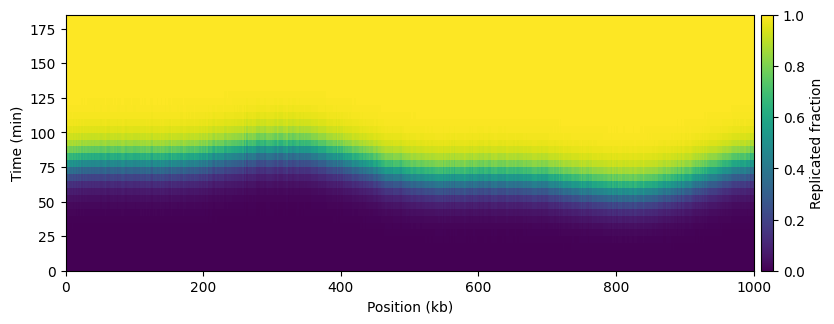

In [6]:
time_min = np.arange(0.0, 181.0, 5.0)
field = 1.0 / (1.0 + np.exp(-(time_min[None, :] - mean[:, None]) / 8.0))
plotf(
    field,
    x_array=positions_kb,
    time_array=time_min,
    xtitle="Position (kb)",
    ytitle="Time (min)",
    labels=["Replicated fraction"],
    limsz=(0.0, 1.0),
    figsize=(8, 3.2),
)


### Logarithmic axes with zero values

Logarithms require positive values. In this static figure, mask zeros and missing values explicitly and let the minimum positive value set the colour range. This preserves zero-valued data in the original array and avoids an arbitrary numerical floor.


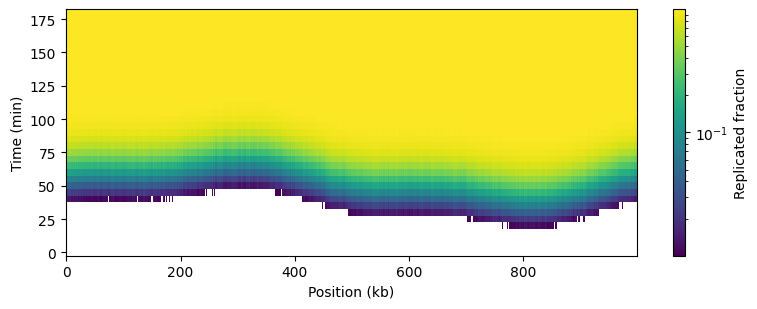

In [7]:
from matplotlib.colors import LogNorm

positive_field = field.copy()
positive_field[positive_field < 0.01] = 0.0
shown = np.ma.masked_where(
    ~np.isfinite(positive_field) | (positive_field <= 0), positive_field
)
fig, ax = plt.subplots()
image = ax.pcolormesh(
    positions_kb,
    time_min,
    shown.T,
    shading="auto",
    norm=LogNorm(vmin=shown.min(), vmax=shown.max()),
    cmap="viridis",
)
ax.set(xlabel="Position (kb)", ylabel="Time (min)")
fig.colorbar(image, ax=ax, label="Replicated fraction")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fraction_log_colour.png", dpi=180, bbox_inches="tight")
plt.show()


## 4. Interactive circular tracks

Use the same headless renderer as the app for an HTML chart with an editable legend, hover values and circular navigation. `track_height` is a percentage (1–24); `inner_radius` controls the central space. Multiple tracks can use separate rings or one combined ring. A circular display does not change the model's boundary conditions.


In [8]:
base_style = dict(
    title="",
    x_label="Position (kb)",
    y_label="Replication timing (min)",
    color="#b03412",
    palette="viridis",
    histogram_bins=20,
    density=False,
    show_legend=True,
    show_colorbar=False,
    log_y=False,
    invert_y=False,
    y_limits=None,
    series_label="Timing",
    legend_position="Top right",
    aspect_ratio=2.5,
)
lines = [PreviewLine("Mean timing", positions_kb, mean, "#b03412")]
bands = [PreviewBand("±1 SD", positions_kb, mean - std, mean + std, "#b03412")]
cartesian = build_preview_plot_options(
    plot_type="Line", lines=lines, bands=bands, **base_style
)
circular = circular_preview_options(
    cartesian, layout="Rings", track_height=5.0, inner_radius=64.0
)
circular_path = write_plot_html(
    circular, OUTPUT_DIR / "timing_circular.html", title="Circular timing profile"
)
assert circular["dnascapeAspectRatio"] == 1.0
print(f"Open in a browser: {circular_path}")


Open in a browser: C:\Users\Francisco Berkemeier\Dropbox\Main Work\PostDoc\My Papers\DNAscape\github\DNAscape-devmode\examples\outputs\plotting\timing_circular.html


### Separate or combined circular tracks

The curves keep their original genomic angular positions when a slice is enlarged. The legend remains outside the circle. This example exports two individual profiles as separate rings; change `layout` to `"Combined"` to overlay them.


In [9]:
multi_options = build_preview_plot_options(
    plot_type="Line",
    lines=[
        PreviewLine("Profile 1", positions_kb, individual_profiles[0], "#b03412"),
        PreviewLine("Profile 2", positions_kb, individual_profiles[1], "#3498b8"),
    ],
    **base_style,
)
separate_rings = circular_preview_options(
    multi_options, layout="Rings", track_height=3.0, inner_radius=60.0
)
write_plot_html(
    separate_rings,
    OUTPUT_DIR / "individual_circular_tracks.html",
    title="Individual circular tracks",
)
print("Saved timing_circular.html and individual_circular_tracks.html")


Saved timing_circular.html and individual_circular_tracks.html


### A combined histogram with statistics

The interactive histogram uses the app's shared guide panel. Click a bar or use the panel selector to inspect a dataset's statistics. Export statistics separately when the numeric summary is needed in downstream analyses.


In [10]:
histogram_lines = [
    PreviewLine(label, np.arange(values.size), values, color)
    for (label, values), color in zip(samples.items(), ["#b03412", "#3498b8"])
]
histogram = build_preview_plot_options(
    plot_type="Histogram",
    lines=histogram_lines,
    show_histogram_statistics=True,
    histogram_bin_size=5.0,
    **{**base_style, "x_label": "Completion time (min)", "y_label": "Count"},
)
write_plot_html(
    histogram,
    OUTPUT_DIR / "combined_histogram.html",
    title="Completion time distributions",
)
assert (OUTPUT_DIR / "statistics.tsv").exists()
print("Saved combined_histogram.html and statistics.tsv")


Saved combined_histogram.html and statistics.tsv


## 5. Export and navigation

- **Static figures:** SVG preserves editable text and paths; PNG is useful for slides. Use `figsize` for the physical aspect ratio and `dpi` for raster resolution.
- **HTML:** open the generated file in a browser. It loads a pinned ECharts runtime from a CDN, so first loading requires internet. Supply `echarts_source` to `write_plot_html` to embed a locally available runtime for an offline HTML file.
- **Circular navigation:** drag to pan the view, hold **left Ctrl + scroll** to zoom, or **left Ctrl + drag** to enlarge the smaller selected slice. Hover shows a radial guide and nearby values; the plotted genomic angles retain their original positions.
- **App previews:** ordinary drag pans within the original axis bounds. Left Ctrl + drag selects an x interval, or an x–y box in a heatmap. Restore limits using the reset controls in Plot settings; Guides → Hover controls cursor readouts.

Return to the [quickstart](0-quickstart.ipynb), [mapping atlas](2-mapping.ipynb) or [simulation examples](3-simulation.ipynb).
